# Is Congestion Pricing Working? Manhattan Traffic After the Toll
**Data with Mehreen · Week 1: Get the data and explore it**

**Dataset:** [MTA Congestion Relief Zone Vehicle Entries: Beginning 2025](https://data.ny.gov/d/t6yz-b64h) (NY Open Data, `t6yz-b64h`)

Each raw row counts the vehicles entering Manhattan's Congestion Relief Zone (CRZ) in one **10-minute block**, at one of **12 crossings**, for one **vehicle class**. That's millions of rows, so we **don't download the raw file**. Instead, we ask the API to add the numbers up for us (like a SQL `GROUP BY`) and download only the small summarized tables.

### Questions for Week 1
1. How many vehicles enter the zone per day, and is that changing over time?
2. Which vehicle types make up the traffic?
3. Which crossings (tunnels and bridges) are busiest?
4. How does traffic differ by day of the week?
5. *(Teaser for Week 2)* What does a typical day look like hour by hour?

## 1. Setup

In [1]:
# If needed: pip install pandas matplotlib requests
from pathlib import Path
import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

API_URL = "https://data.ny.gov/resource/t6yz-b64h.json"

## 2. Helper: ask the API for summarized data
The NY Open Data API understands **SoQL**, a SQL-like query language. We send `select` / `group` / `order`, and it returns the aggregated rows.

Results are saved to `data/` as CSVs, so the API is only called once. Delete a CSV to re-download fresh data.

In [2]:
def fetch_soql(select, group, order, name, where=None, page_size=50_000):
    """Run an aggregated SoQL query (with paging) and cache the result as CSV."""
    cache = DATA_DIR / f"{name}.csv"
    if cache.exists():
        print(f"Loaded cached {cache}")
        return pd.read_csv(cache)

    rows, offset = [], 0
    while True:
        params = {"$select": select, "$group": group, "$order": order,
                  "$limit": page_size, "$offset": offset}
        if where:
            params["$where"] = where
        r = requests.get(API_URL, params=params, timeout=120)
        r.raise_for_status()
        batch = r.json()
        rows.extend(batch)
        print(f"  {name}: fetched {len(rows):,} rows")
        if len(batch) < page_size:
            break
        offset += page_size

    df = pd.DataFrame(rows)
    df.to_csv(cache, index=False)
    return df

## 3. Pull three small summary tables
| Table | Grouped by | Approx. rows | Used for |
|---|---|---|---|
| `daily_by_class` | date × vehicle class | ~4,000 | trend over time, vehicle mix, day of week |
| `daily_by_crossing` | date × crossing | ~8,000 | busiest tunnels/bridges |
| `weekly_hourly` | week × hour × vehicle class | ~13,000 | hour-of-day patterns (Week 2) |

In [3]:
daily_by_class = fetch_soql(
    select="toll_date, vehicle_class, sum(crz_entries) AS entries",
    group="toll_date, vehicle_class",
    order="toll_date, vehicle_class",
    name="daily_by_class",
)

daily_by_crossing = fetch_soql(
    select="toll_date, detection_group, detection_region, sum(crz_entries) AS entries",
    group="toll_date, detection_group, detection_region",
    order="toll_date, detection_group",
    name="daily_by_crossing",
)

weekly_hourly = fetch_soql(
    select="toll_week, hour_of_day, vehicle_class, time_period, sum(crz_entries) AS entries",
    group="toll_week, hour_of_day, vehicle_class, time_period",
    order="toll_week, hour_of_day, vehicle_class",
    name="weekly_hourly",
)

daily_by_class.head()

Loaded cached data/daily_by_class.csv
Loaded cached data/daily_by_crossing.csv
Loaded cached data/weekly_hourly.csv


,toll_date,vehicle_class,entries
0,2025-01-05T00:00:00.000,"1 - Cars, Pickups and Vans",253836
1,2025-01-05T00:00:00.000,2 - Single-Unit Trucks,5254
2,2025-01-05T00:00:00.000,3 - Multi-Unit Trucks,615
3,2025-01-05T00:00:00.000,4 - Buses,3480
4,2025-01-05T00:00:00.000,5 - Motorcycles,1486


## 4. Clean
- Turn dates into real dates and entries into numbers
- Shorten vehicle class labels for charts
- Drop the **last, incomplete week** so it doesn't look like a sudden drop. The dataset is updated with a delay, so the newest week is often partial.

In [4]:
VEHICLE_LABELS = {
    "1 - Cars, Pickups and Vans": "Cars/Pickups/Vans",
    "2 - Single-Unit Trucks": "Single-unit trucks",
    "3 - Multi-Unit Trucks": "Multi-unit trucks",
    "4 - Buses": "Buses",
    "5 - Motorcycles": "Motorcycles",
    "TLC Taxi/FHV": "Taxi / Uber / Lyft",
}

def clean(df, date_col):
    df = df.copy()
    df[date_col] = pd.to_datetime(df[date_col]).dt.tz_localize(None)
    df["entries"] = pd.to_numeric(df["entries"])
    if "vehicle_class" in df:
        df["vehicle"] = df["vehicle_class"].map(VEHICLE_LABELS).fillna(df["vehicle_class"])
    if "hour_of_day" in df:
        df["hour_of_day"] = pd.to_numeric(df["hour_of_day"]).astype(int)
    return df

daily_by_class    = clean(daily_by_class, "toll_date")
daily_by_crossing = clean(daily_by_crossing, "toll_date")
weekly_hourly     = clean(weekly_hourly, "toll_week")

# Keep only complete weeks (weeks start on Sunday in this dataset)
last_date = daily_by_class["toll_date"].max()
cutoff = last_date - pd.Timedelta(days=(last_date.dayofweek - 5) % 7)  # most recent Saturday
last_full_week_start = cutoff - pd.Timedelta(days=6)                   # its Sunday

daily_by_class    = daily_by_class[daily_by_class["toll_date"] <= cutoff]
daily_by_crossing = daily_by_crossing[daily_by_crossing["toll_date"] <= cutoff]
weekly_hourly     = weekly_hourly[weekly_hourly["toll_week"] <= last_full_week_start]

print("Date range:", daily_by_class["toll_date"].min().date(), "to", cutoff.date())
print("Total zone entries:", f"{daily_by_class['entries'].sum():,.0f}")

Date range: 2025-01-05 to 2026-11-07
Total zone entries: 325,780,282


### Quick sanity checks
Good habit: check the data before believing any chart.

In [5]:
daily_total = daily_by_class.groupby("toll_date")["entries"].sum()

print("Days:", daily_total.size)
print("Missing days:", pd.date_range(daily_total.index.min(), daily_total.index.max()).difference(daily_total.index).size)
print("\nDaily entries summary:")
print(daily_total.describe().round(0))
print("\nLowest 5 days (holidays? storms?):")
print(daily_total.nsmallest(5))

Days: 672
Missing days: 0

Daily entries summary:
count       672.0
mean     484792.0
std       44092.0
min       64167.0
25%      468634.0
50%      491782.0
75%      511602.0
max      557583.0
Name: entries, dtype: float64

Lowest 5 days (holidays? storms?):
toll_date
2026-02-23     64167
2026-01-25    117548
2026-01-26    195624
2026-02-22    283668
2025-12-27    331518
Name: entries, dtype: int64


**What the sanity check found:** the lowest days aren't data errors. They are real events:
- **Jan 25–26, 2026:** the biggest NYC snowstorm in years
- **Feb 22–24, 2026:** a blizzard, with a citywide travel ban until noon on Feb 23. Entries fell to ~64K, about 87% below a normal day.
- Holidays (July 4, Christmas, Dec 27) are also low.

Keep these in mind: they pull down the January and February averages for 2026.

## 5. Explore
### Q1: How many vehicles enter per day, and is it changing?

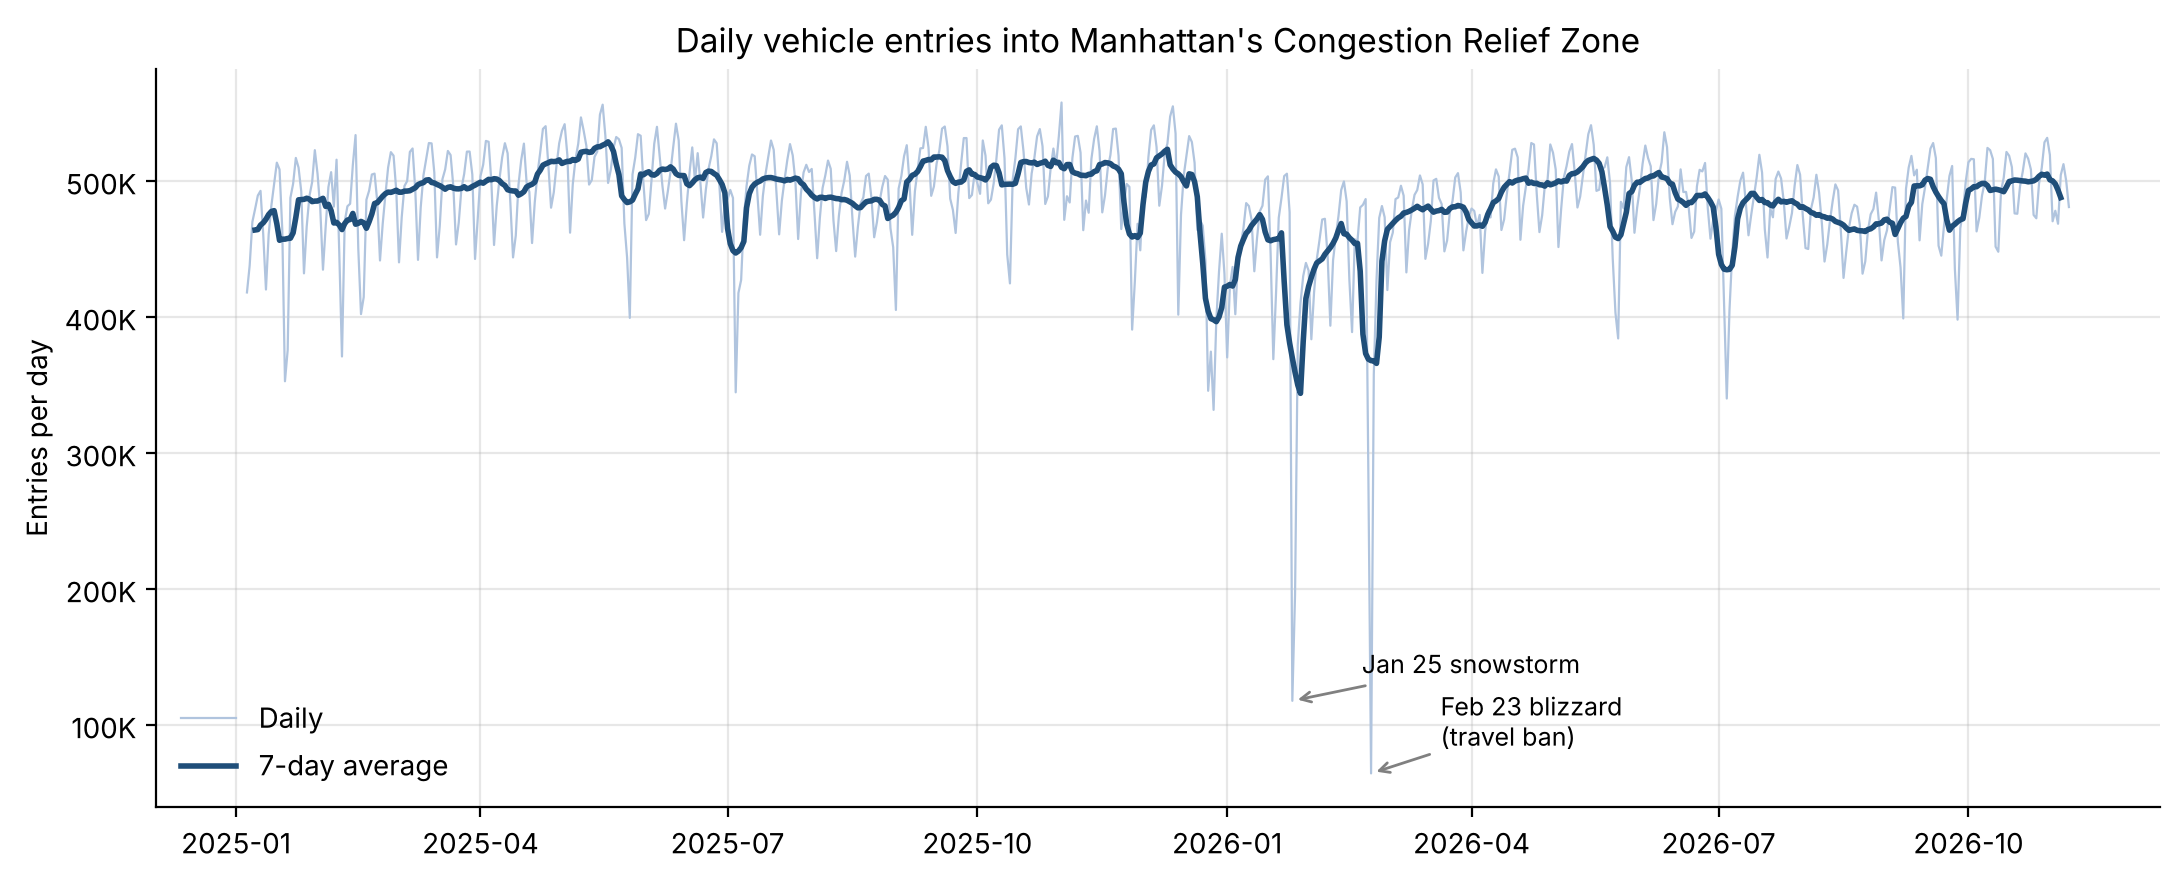

In [6]:
rolling = daily_total.rolling(7, center=True).mean()

fig, ax = plt.subplots()
ax.plot(daily_total.index, daily_total, color="#b0c4de", lw=0.8, label="Daily")
ax.plot(rolling.index, rolling, color="#1f4e79", lw=2, label="7-day average")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
# Label the big outliers (found in the sanity check above)
EVENTS = {"2026-01-25": "Jan 25 snowstorm", "2026-02-23": "Feb 23 blizzard\n(travel ban)"}
for day, label in EVENTS.items():
    day = pd.Timestamp(day)
    if day in daily_total.index:
        ax.annotate(label, xy=(day, daily_total[day]), xytext=(25, 10),
                    textcoords="offset points", fontsize=9,
                    arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_title("Daily vehicle entries into Manhattan's Congestion Relief Zone")
ax.set_ylabel("Entries per day")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [7]:
# Same months, year over year: is traffic still falling?
# Only compare FULL months (the newest month is usually partial).
# Median is shown too, because storm days drag the mean down.
daily = daily_total.to_frame("entries")
days_in_month = daily.groupby(daily.index.to_period("M")).size()
full_months = days_in_month[days_in_month == days_in_month.index.days_in_month].index
daily = daily[daily.index.to_period("M").isin(full_months)]

monthly = daily.groupby([daily.index.month, daily.index.year])["entries"].agg(["mean", "median"])
yoy = monthly.unstack().round(0)
yrs = sorted(daily.index.year.unique())
if len(yrs) >= 2:
    a, b = yrs[-2], yrs[-1]
    yoy["mean_change_%"] = ((yoy[("mean", b)] / yoy[("mean", a)] - 1) * 100).round(1)
    yoy["median_change_%"] = ((yoy[("median", b)] / yoy[("median", a)] - 1) * 100).round(1)
yoy.index.name = "month"
yoy

mean              median           mean_change_% median_change_%
toll_date      2025      2026      2025      2026                              
month                                                                          
1               NaN  431188.0       NaN  446702.0           NaN             NaN
2          477354.0  431152.0  483846.0  456654.0          -9.7            -5.6
3          493047.0  475608.0  499816.0  482835.0          -3.5            -3.4
4          501873.0  489988.0  504268.0  490602.0          -2.4            -2.7
5          512925.0  494334.0  521406.0  503756.0          -3.6            -3.4
6          502433.0  492966.0  500249.0  491782.0          -1.9            -1.7
7          488965.0  475462.0  496160.0  483981.0          -2.8            -2.5
8          484030.0  468047.0  487215.0  470564.0          -3.3            -3.4
9          503934.0  480319.0  506869.0  490144.0          -4.7            -3.3
10         507964.0  500292.0  515826.0  508358.0          -1.5            -1.4
11         496765.0       NaN  496605.0       NaN           NaN             NaN
12         479158.0       NaN  491036.0       NaN           NaN             NaN

In [8]:
# One headline number: same date range in both years (Jan 5 to Oct 31)
y25 = daily_total["2025-01-05":"2025-10-31"]
y26 = daily_total["2026-01-05":"2026-10-31"]
print(f"Avg daily entries, Jan 5–Oct 31 2025: {y25.mean():,.0f}")
print(f"Avg daily entries, Jan 5–Oct 31 2026: {y26.mean():,.0f}")
print(f"Change: {(y26.mean() / y25.mean() - 1) * 100:+.1f}%")

Avg daily entries, Jan 5–Oct 31 2025: 494,821
Avg daily entries, Jan 5–Oct 31 2026: 475,107
Change: -4.0%


### Q2: Which vehicle types make up the traffic?

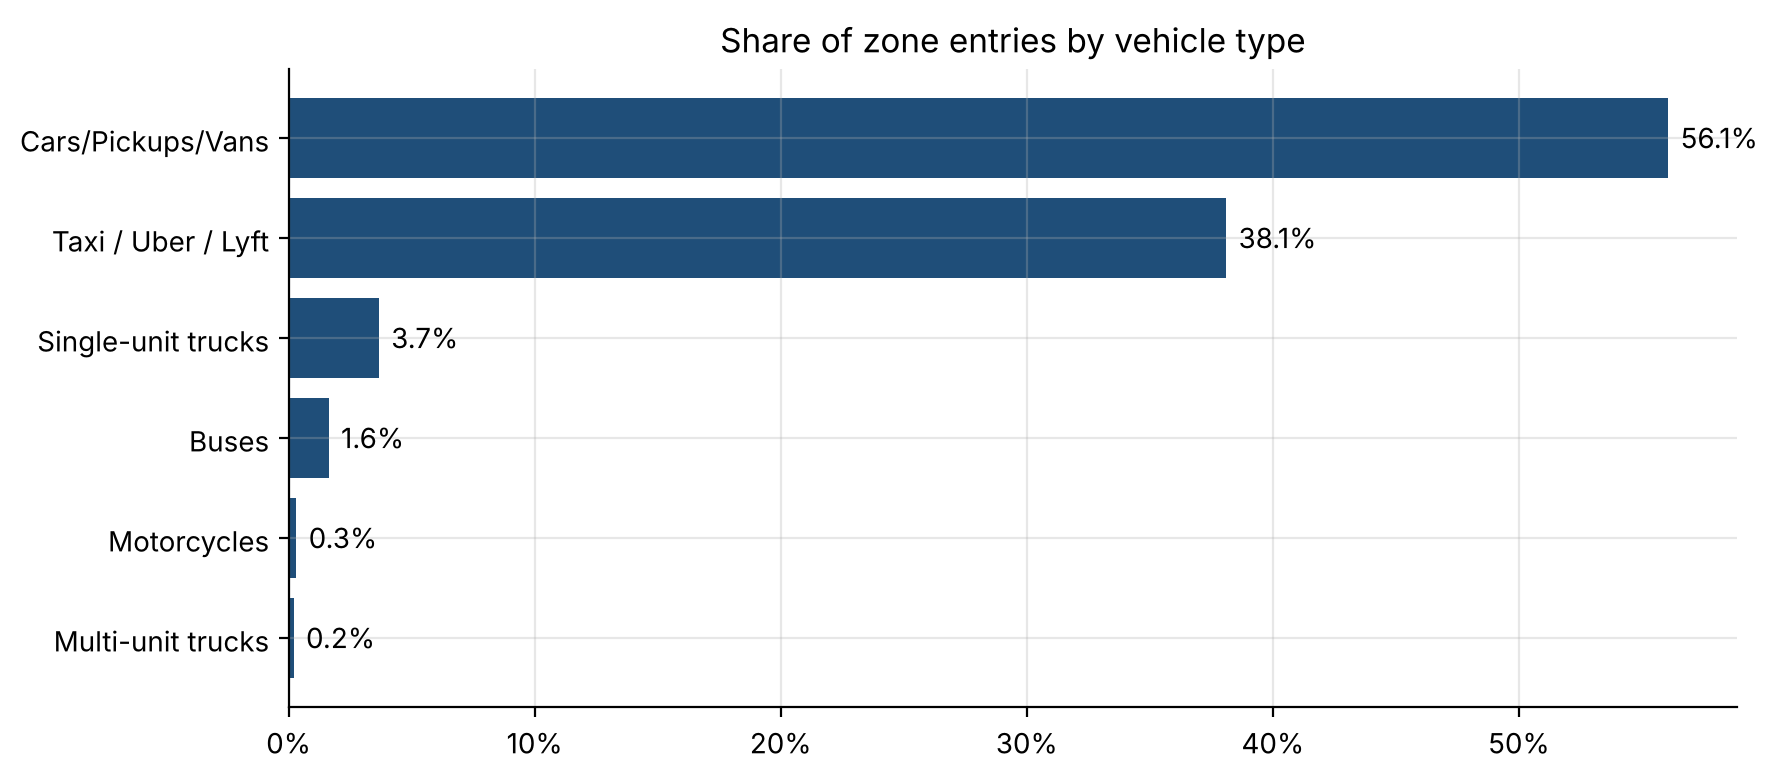

In [9]:
mix = (daily_by_class.groupby("vehicle")["entries"].sum()
       .sort_values(ascending=True))
share = mix / mix.sum() * 100

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(share.index, share.values, color="#1f4e79")
for i, v in enumerate(share.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_title("Share of zone entries by vehicle type")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()

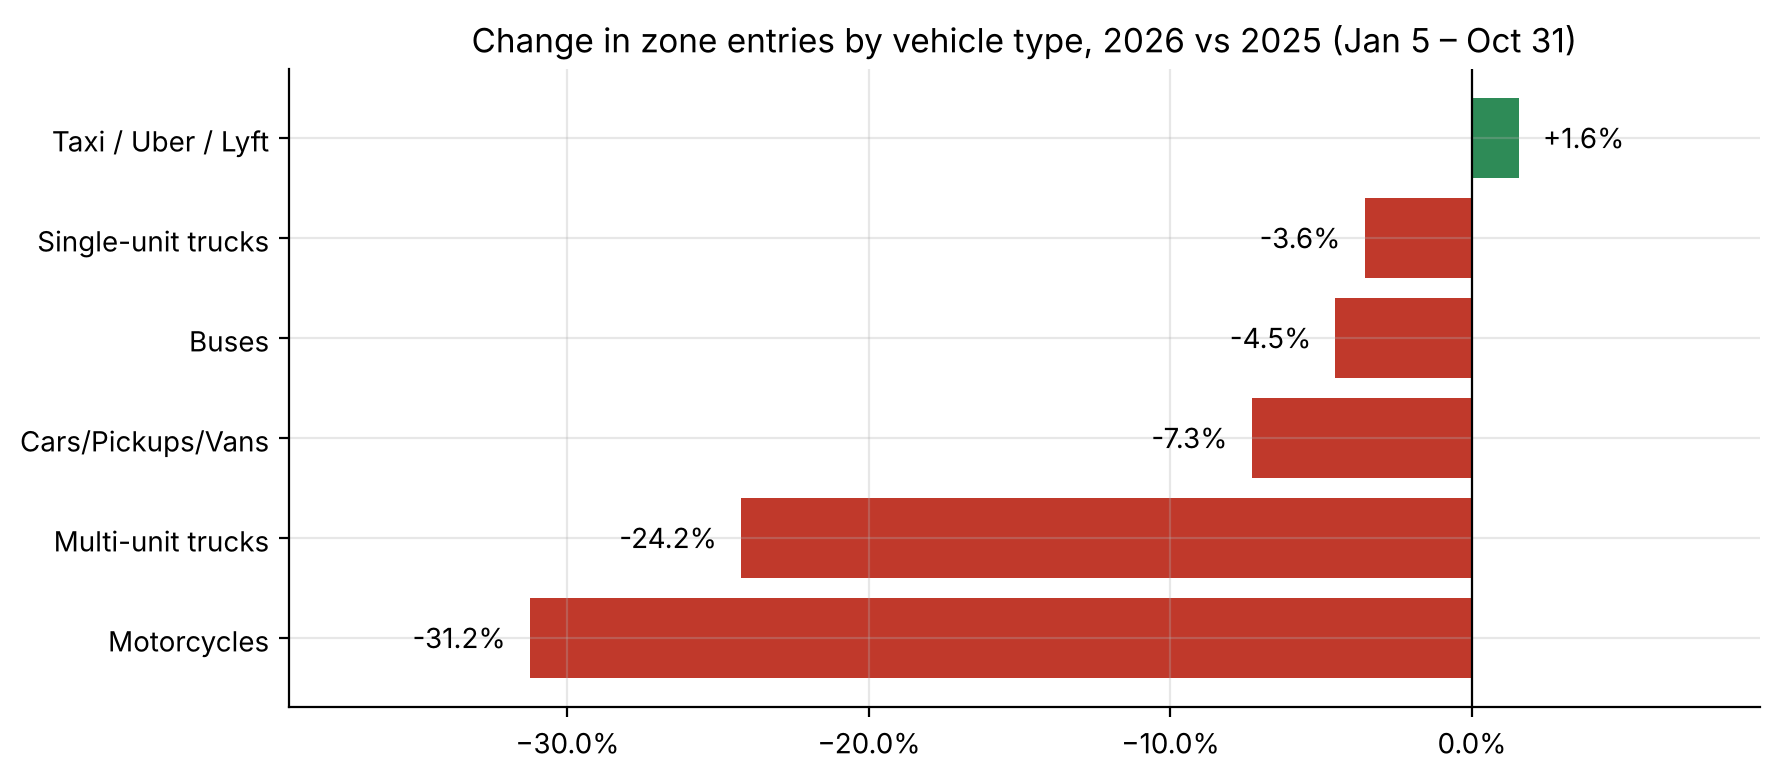

year,2025,2026,change_%
vehicle,,,
Motorcycles,568283,390713,-31.2
Multi-unit trucks,350745,265713,-24.2
Cars/Pickups/Vans,84745056,78550370,-7.3
Buses,2448106,2337248,-4.5
Single-unit trucks,5504139,5308016,-3.6
Taxi / Uber / Lyft,54830047,55680135,1.6


In [10]:
# Has the mix shifted? Compare the same dates in 2025 and 2026 (Jan 5 to Oct 31)
same_dates = daily_by_class[daily_by_class["toll_date"].dt.strftime("%m-%d").between("01-05", "10-31")]
by_year = (same_dates.assign(year=same_dates["toll_date"].dt.year)
           .groupby(["vehicle", "year"])["entries"].sum().unstack())
by_year["change_%"] = (by_year.iloc[:, -1] / by_year.iloc[:, -2] - 1) * 100
by_year = by_year.sort_values("change_%")

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#c0392b" if v < 0 else "#2e8b57" for v in by_year["change_%"]]
ax.barh(by_year.index, by_year["change_%"], color=colors)
for i, v in enumerate(by_year["change_%"]):
    ax.text(v + (0.8 if v >= 0 else -0.8), i, f"{v:+.1f}%", va="center",
            ha="left" if v >= 0 else "right")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Change in zone entries by vehicle type, 2026 vs 2025 (Jan 5 – Oct 31)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(by_year["change_%"].min() - 8, max(by_year["change_%"].max(), 0) + 8)
plt.tight_layout(); plt.show()
by_year.round(1)

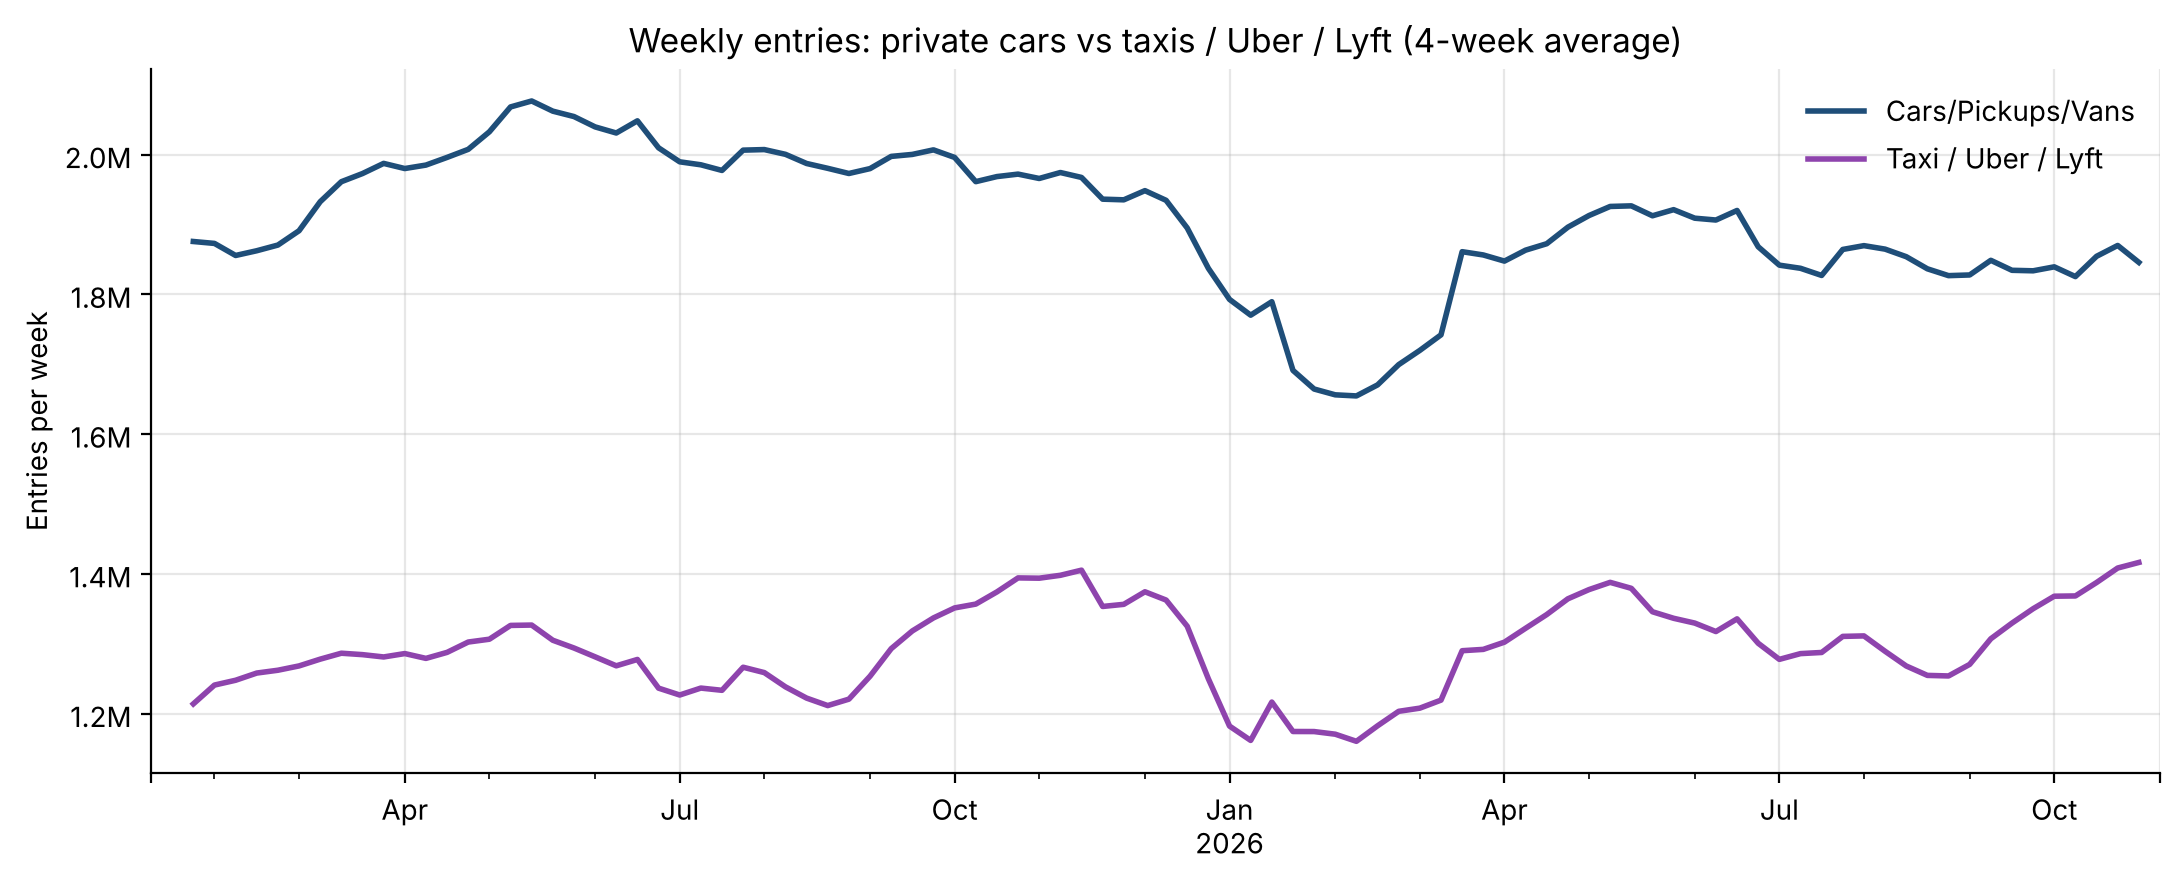

In [11]:
# The two big groups over time: private cars vs taxis / Uber / Lyft (4-week average)
weekly = (daily_by_class.set_index("toll_date")
          .groupby("vehicle")["entries"].resample("W-SAT").sum().unstack(0))
two = weekly[["Cars/Pickups/Vans", "Taxi / Uber / Lyft"]].rolling(4, center=True).mean()

fig, ax = plt.subplots()
two.plot(ax=ax, lw=2, color=["#1f4e79", "#8e44ad"])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.set_title("Weekly entries: private cars vs taxis / Uber / Lyft (4-week average)")
ax.set_ylabel("Entries per week"); ax.set_xlabel("")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### Q3: Which crossings are busiest?

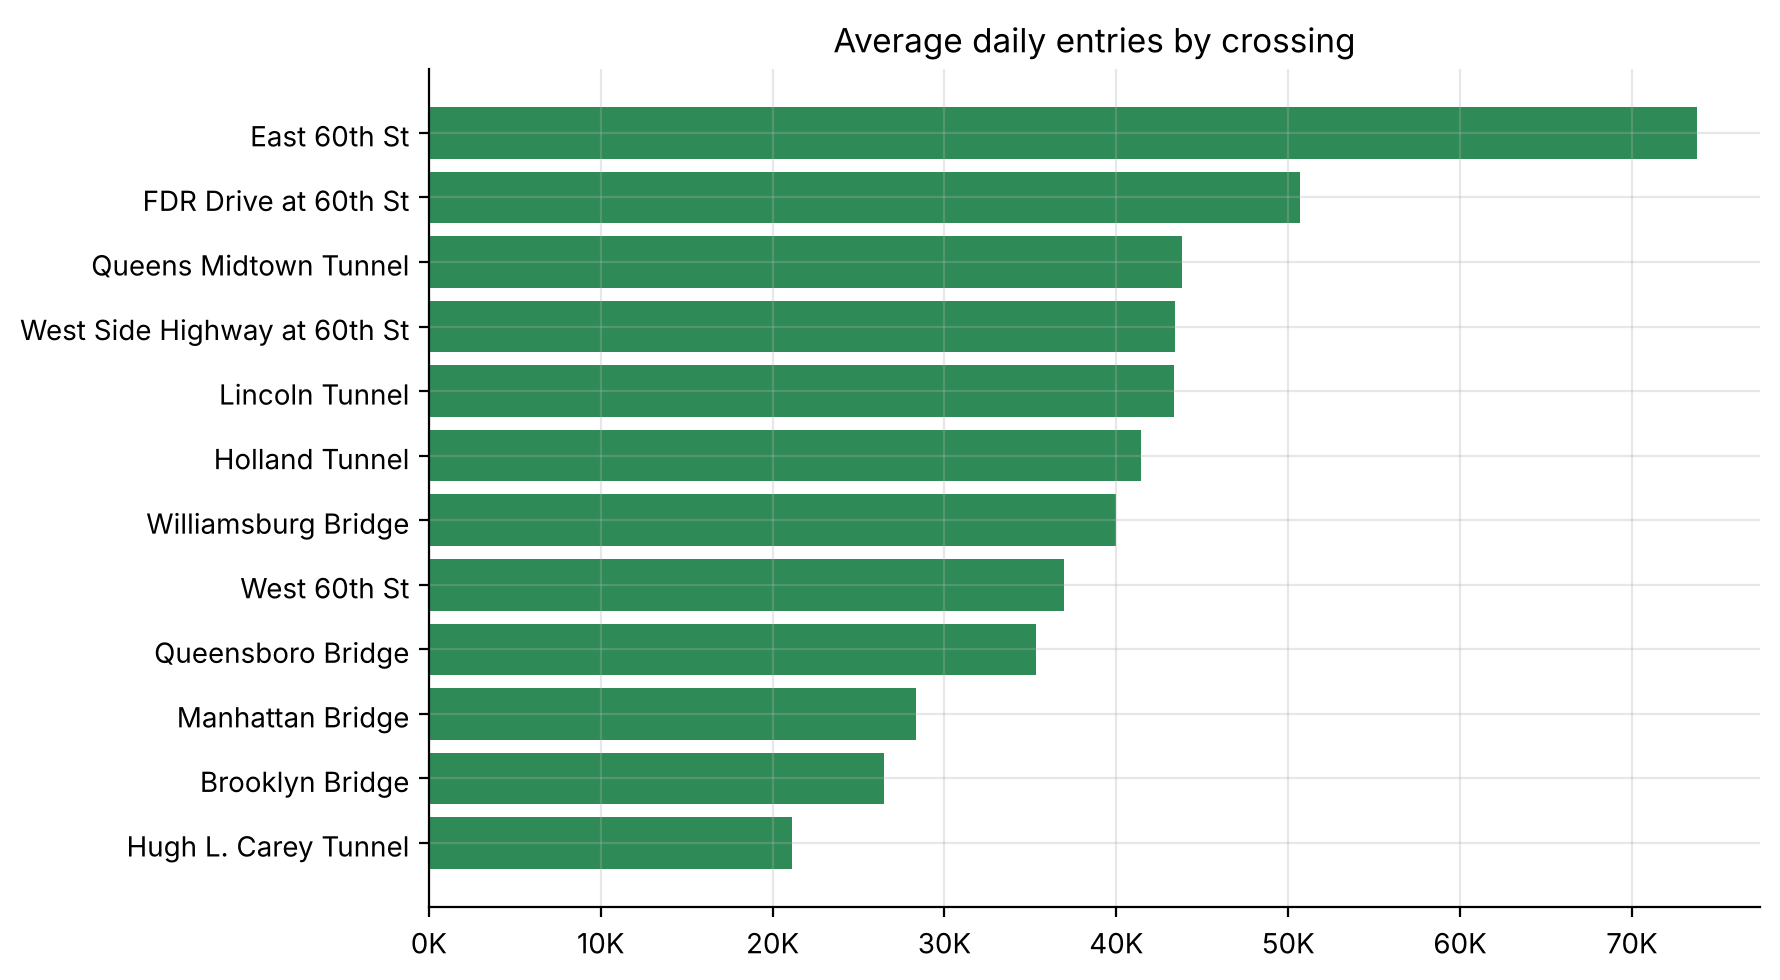

In [12]:
by_crossing = (daily_by_crossing.groupby("detection_group")["entries"].sum()
               / daily_by_crossing["toll_date"].nunique()).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(by_crossing.index, by_crossing.values, color="#2e8b57")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
ax.set_title("Average daily entries by crossing")
plt.tight_layout(); plt.show()

### Q4: How does traffic differ by day of week?

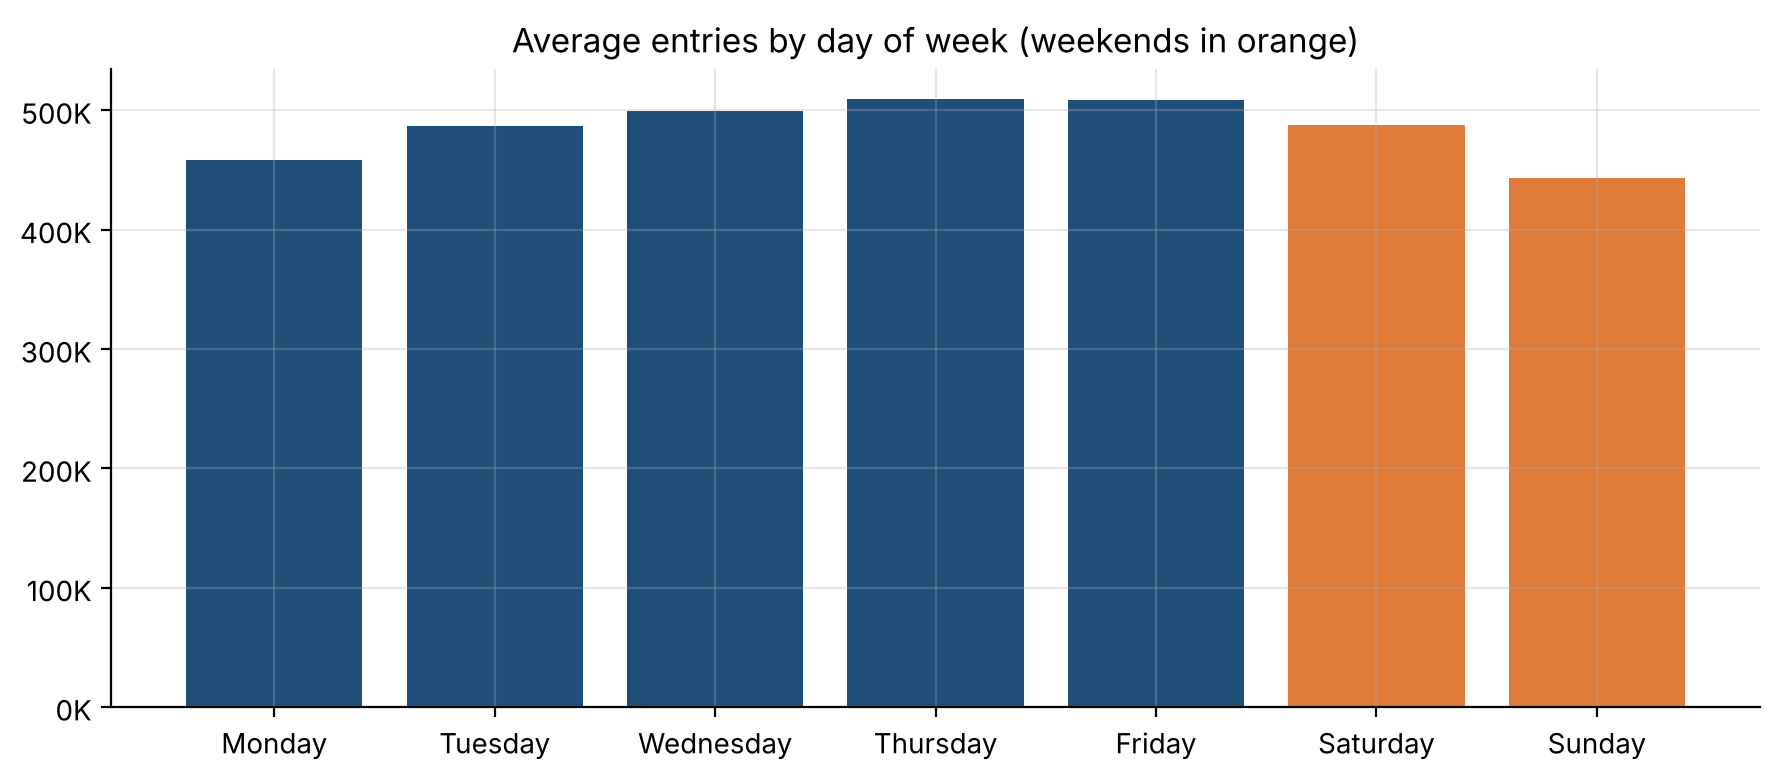

In [13]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = (daily_total.to_frame("entries")
       .assign(day=lambda d: d.index.day_name())
       .groupby("day")["entries"].mean().reindex(dow_order))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(dow.index, dow.values, color=["#1f4e79"] * 5 + ["#e07b39"] * 2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
ax.set_title("Average entries by day of week (weekends in orange)")
plt.tight_layout(); plt.show()

### Q5 (teaser for Week 2): What does a typical day look like?
Peak toll hours are when drivers pay the most. If drivers are dodging the toll, we'd expect a bump in the **overnight hours just before peak pricing starts**. Week 2 digs into this.

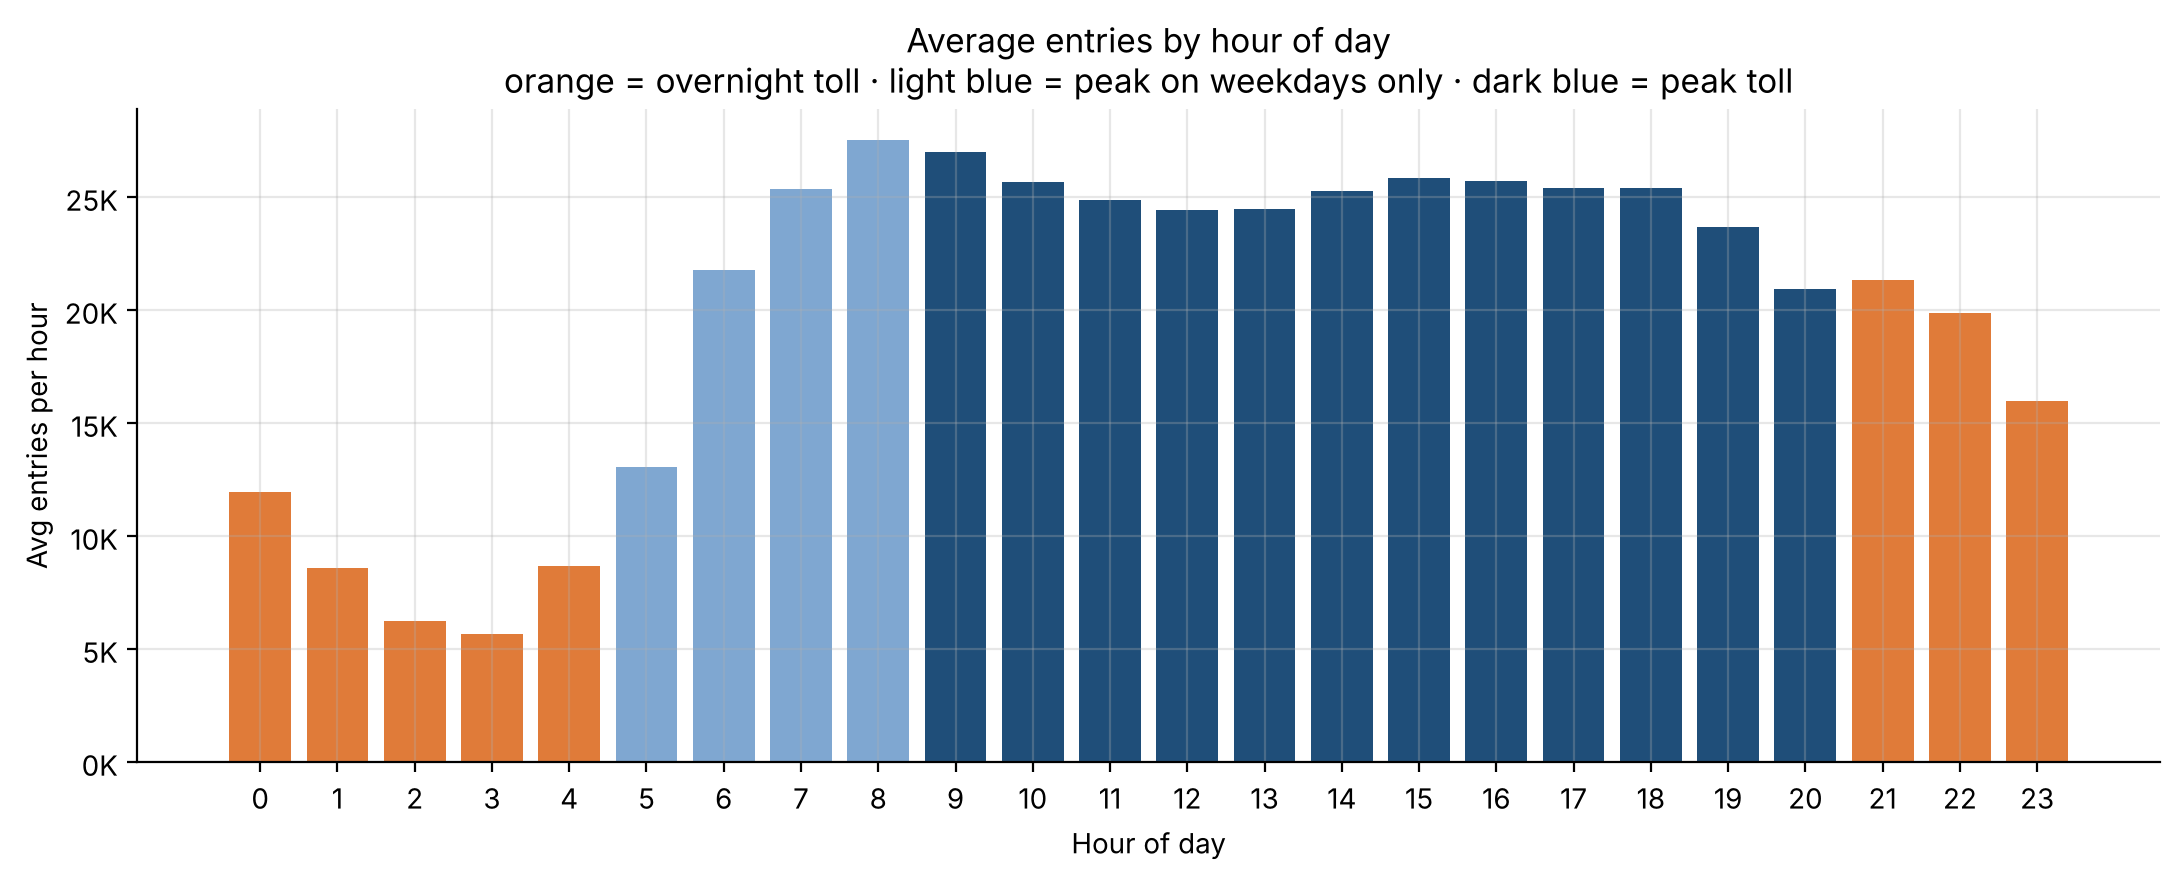

3am → 4am jump: 5,667 → 8,683 (+53%), the hour before weekday peak pricing starts


In [14]:
n_weeks = weekly_hourly["toll_week"].nunique()
hourly = weekly_hourly.groupby("hour_of_day")["entries"].sum() / (n_weeks * 7)  # avg per day

# Peak hours differ between weekdays and weekends, so some hours are "peak" only on weekdays.
peak_share = (weekly_hourly.assign(is_peak=weekly_hourly["time_period"].eq("Peak"))
              .groupby("hour_of_day")["is_peak"].mean())
def period_color(share):
    if share == 0:  return "#e07b39"   # always overnight toll
    if share == 1:  return "#1f4e79"   # always peak toll
    return "#7fa7d1"                   # peak on weekdays only
colors = [period_color(peak_share[h]) for h in hourly.index]

fig, ax = plt.subplots()
ax.bar(hourly.index, hourly.values, color=colors)
ax.set_xticks(range(24))
ax.set_title("Average entries by hour of day\n"
             "orange = overnight toll · light blue = peak on weekdays only · dark blue = peak toll")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Avg entries per hour")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout(); plt.show()

print(f"3am → 4am jump: {hourly[3]:,.0f} → {hourly[4]:,.0f} "
      f"({(hourly[4] / hourly[3] - 1) * 100:+.0f}%), the hour before weekday peak pricing starts")

## 6. My Week 1 findings ✍️
*Data through Saturday, Nov 7, 2026. Re-run with fresh data and these numbers may shift slightly.*

1. **Daily volume:** about **485K vehicles** enter the zone on an average day (median ~492K).
2. **Trend:** from Jan 5 to Oct 31, traffic is **4.0% lower in 2026 than in 2025** (~475K vs ~495K per day). Every full month from February to October is down 1.4–5.6% (median).
3. **Vehicle mix:** **56% are private cars/pickups/vans** and **38% are taxis/Uber/Lyft**.
4. **The shift:** private cars are **down 7.3%** year over year, but taxis/Uber/Lyft are **up 1.6%**. The drop comes from private cars, not ride-hail.
5. **Busiest entry:** **East 60th St** (local streets coming down from the Upper East Side), ~74K per day. The busiest tunnels are Queens Midtown and Lincoln, ~43–44K each.
6. **Weekly rhythm:** Thursday and Friday are busiest (~509K). Sunday is quietest (~443K).
7. **Biggest surprise:** on **Feb 23, 2026**, the blizzard and citywide travel ban cut entries to **~64K, about 87% below a normal day**.
8. **Week 2 teaser:** entries jump **53% from 3am to 4am**, the hour right before weekday peak pricing starts at 5am. Toll-dodging? 👀

### 📣 Post #1 draft
> I analyzed 325 million vehicle entries into Manhattan's congestion pricing zone. 🚗🚕
>
> One year in, traffic is down 4%, but not for everyone:
> 🔻 Private cars: −7.3%
> 🔺 Taxis, Uber & Lyft: +1.6%
>
> Ride-hail now makes up 38% of all entries into the zone.
>
> Fun fact: during February's blizzard travel ban, entries fell 87% in a single day.
>
> Next week: are drivers timing their trips to dodge the toll? The 4am data looks suspicious 👀
>
> #DataScience #NYC #CongestionPricing #Python #DataWithMehreen

## Notes and caveats
- This dataset starts **January 5, 2025, when tolling began**, so it has no "before toll" baseline. A true before/after comparison needs another source (planned for later). January isn't in the month-by-month table because 2025 only has January 5–31.
- The MTA says this data **should not be used for revenue calculations** (no exemption, payment or repeat-entry info).
- Year-over-year changes can also reflect weather, events, the economy and remote work, not only the toll.
- `crz_entries` counts vehicles that entered the zone. `excluded_roadway_entries` (e.g. FDR Drive / West Side Highway pass-through) are not included here.